In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.decomposition import PCA

df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={"code_dept": str})
df["date"] = pd.to_datetime(df["date_semaine"] + "-1", format="%G-S%V-%u")

CIBLE = "TousAge_asthme_urgences"

EXOS = ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10',
        'NO2', 'O3', 'PM10', 'PM2.5', 'SO2',
        'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1',
        'pression_mer', 'tendance_pression_3h', 'vent_vitesse', 'temperature_kelvin',
        'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h',
        'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers',
        'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure',
        'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages',
        'tp_tempete_poussiere_chasse_neige',
        'TousAge_allergie_urgences', 'TousAge_asthme_hospitalisation',
        '0an_bronchiolite_urgences', 'TousAge_allergie_hospitalisation',
        'prev_calc_Maladie_Respi_Chronique_0-14_9',
        'prev_calc_Maladie_Respi_Chronique_15-64_9',
        'prev_calc_Maladie_Respi_Chronique_65+_9',
        'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes',
        'pct_ouvriers', 'pct_retraites', 'pct_agriculteurs',
        'densite_generalistes', 'densite_pediatres', 'densite_pneumologues',
        'densite_allergologues', 'densite_kines',
        'sos_present']

H = 1  # nombre de semaines futures des la cible

# une ligne par département et par semaine t, cible = moyenne de y(t+1) à y(t+H)
morceaux = []
for dept, d in df.groupby("code_dept"):
    d = d.drop_duplicates("date").set_index("date").sort_index().asfreq("W-MON")
    y, sem = d[CIBLE], d.index.isocalendar().week.astype(float)
    moy_glis = y.rolling(H, min_periods=H).mean() 
    bloc = pd.DataFrame({
        "code_dept": dept,
        "date_debut": d.index + pd.Timedelta(weeks=1),  
        "date_fin": d.index + pd.Timedelta(weeks=H),  
        "cible": moy_glis.shift(-H),
        "y_passe": moy_glis,
        "y_lag0": y, "y_lag1": y.shift(1), "y_lag2": y.shift(2),
        "sem_sin": np.sin(2 * np.pi * sem / 52.18),
        "sem_cos": np.cos(2 * np.pi * sem / 52.18),
    })
    for c in EXOS:
        bloc[c] = d[c]
    morceaux.append(bloc)
panel = pd.concat(morceaux).dropna(subset=["cible", "y_passe", "y_lag0", "y_lag1", "y_lag2"])

an = panel["date_fin"].dt.year
panel["split"] = "test"
panel.loc[an <= 2022, "split"] = "train"
panel.loc[an == 2023, "split"] = "val"

# baseline 1, persistance 
panel["base_persist"] = panel["y_passe"]
# baseline 2, profil saisonnier 
panel["sem_debut"] = panel["date_debut"].dt.isocalendar().week.astype(int)
profil = panel[panel["split"] == "train"].groupby(["code_dept", "sem_debut"])["cible"].mean()
profil = profil.rename("base_saison")
panel = panel.join(profil, on=["code_dept", "sem_debut"])

def scores(y_vrai, y_pred):
    return {"R2": r2_score(y_vrai, y_pred),
            "MAE": mean_absolute_error(y_vrai, y_pred),
            "RMSE": mean_squared_error(y_vrai, y_pred) ** 0.5}

val = panel[panel["split"] == "val"].dropna(subset=["base_saison"])
print(panel["split"].value_counts())
print("Persistance :", scores(val["cible"], val["base_persist"]))
print("Profil saisonnier :", scores(val["cible"], val["base_saison"]))

split
train    9696
val      4992
test     4992
Name: count, dtype: int64
Persistance : {'R2': 0.4622693063340212, 'MAE': 263.2236892592448, 'RMSE': 376.5929746172903}
Profil saisonnier : {'R2': 0.5144792565338587, 'MAE': 252.30392629169552, 'RMSE': 357.8439634026693}


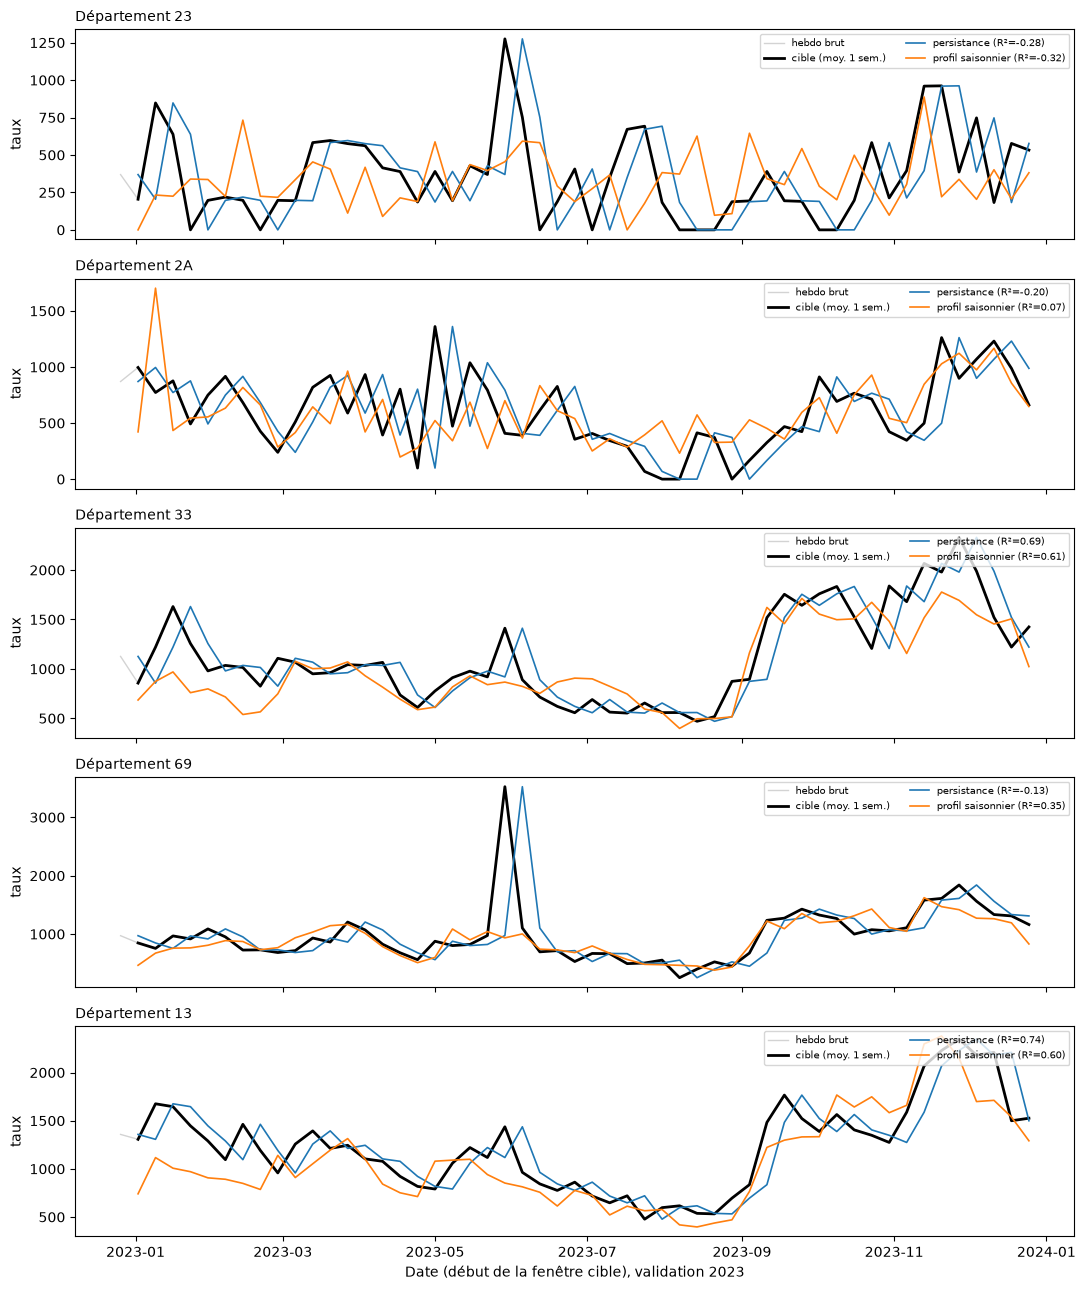

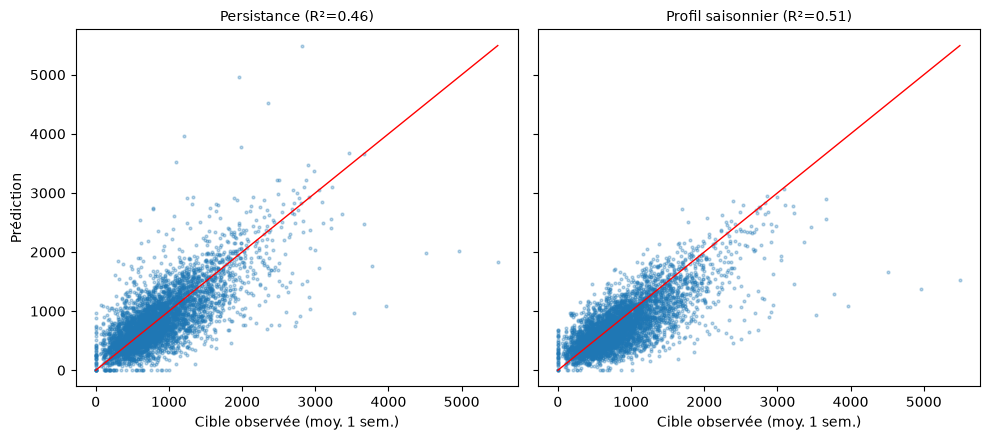

In [2]:
DEPTS = ["23", "2A", "33", "69", "13"] 

fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = val[val["code_dept"] == dept].sort_values("date_debut")
    sc_p = scores(v["cible"], v["base_persist"])["R2"]
    sc_s = scores(v["cible"], v["base_saison"])["R2"]

    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["date_debut"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    ax.plot(v["date_debut"], v["base_persist"], color="tab:blue", lw=1.2,
            label=f"persistance (R²={sc_p:.2f})")
    ax.plot(v["date_debut"], v["base_saison"], color="tab:orange", lw=1.2,
            label=f"profil saisonnier (R²={sc_s:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (début de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, col, nom in zip(axes, ["base_persist", "base_saison"], ["Persistance", "Profil saisonnier"]):
    ax.scatter(val["cible"], val[col], s=4, alpha=0.3)
    lim = [0, val[["cible", col]].max().max()]
    ax.plot(lim, lim, color="red", lw=1)  # diagonale y = x
    ax.set_title(f"{nom} (R²={scores(val['cible'], val[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

FEATURES = ["y_lag0", "y_lag1", "y_lag2", "sem_sin", "sem_cos"] + EXOS

modele = Pipeline([("scaler", StandardScaler()), ("reg", LinearRegression())])

train = panel[panel["split"] == "train"].dropna(subset=FEATURES + ["cible"])
val_m = panel[panel["split"] == "val"].dropna(subset=FEATURES + ["cible"])

modele.fit(train[FEATURES], train["cible"])
print("LR val :", scores(val_m["cible"], modele.predict(val_m[FEATURES])))

LR val : {'R2': 0.5724870634173754, 'MAE': 235.95991794550423, 'RMSE': 335.23789405359906}


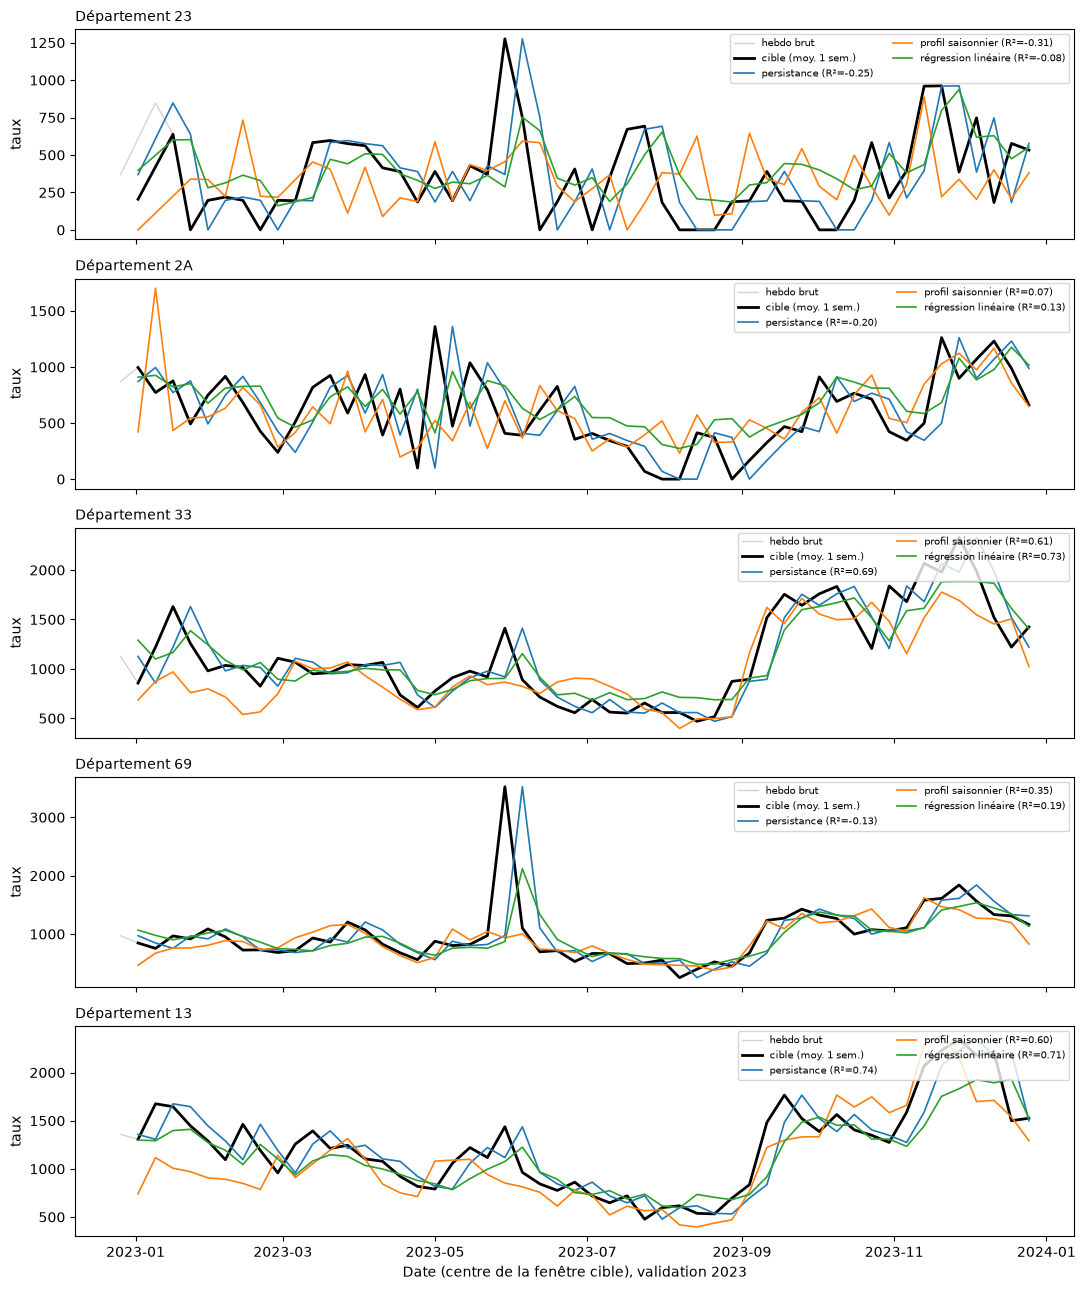

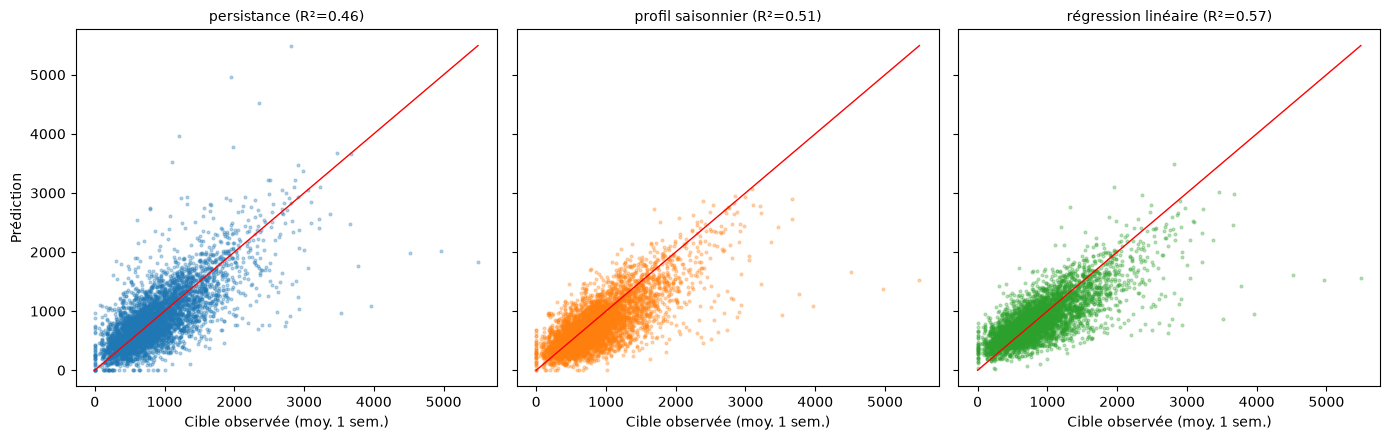

In [4]:
# prédictions du modèle sur validation
v_all = val_m.dropna(subset=["base_saison"]).copy()
v_all["pred_LR"] = modele.predict(v_all[FEATURES])
v_all["centre"] = v_all["date_debut"] + pd.Timedelta(weeks=(H - 1) / 2)

SERIES = [("base_persist", "persistance", "tab:blue"),
          ("base_saison", "profil saisonnier", "tab:orange"),
          ("pred_LR", "régression linéaire", "tab:green")]

# séries temporelles par département
fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = v_all[v_all["code_dept"] == dept].sort_values("date_debut")
    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["centre"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    for col, nom, coul in SERIES:
        r2 = scores(v["cible"], v[col])["R2"]
        ax.plot(v["centre"], v[col], color=coul, lw=1.2, label=f"{nom} (R²={r2:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (centre de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(SERIES), figsize=(14, 4.5), sharex=True, sharey=True)
colonnes = ["cible", "base_persist", "base_saison", "pred_LR"]
lim = [0, v_all[colonnes].max().max()]
for ax, (col, nom, coul) in zip(axes, SERIES):
    ax.scatter(v_all["cible"], v_all[col], s=4, alpha=0.3, color=coul)
    ax.plot(lim, lim, color="red", lw=1)  
    ax.set_title(f"{nom} (R²={scores(v_all['cible'], v_all[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

In [5]:
# indicateurs par département, calculés sur le train uniquement
brut = panel.loc[panel["split"] == "train", ["code_dept", "y_lag0"]].copy()
iso = brut.index.isocalendar()
brut["an"] = iso.year.values
brut["sem"] = iso.week.values


def indicateurs(d):
    # persistance : y(t) prédit par y(t-1)
    y = d.sort_index()["y_lag0"]
    y_prec = y.shift(1)
    r2_persist = r2_score(y[1:], y_prec[1:])

    # saisonnalité : chaque année prédit l'autre, moyenne des deux R²
    piv = d.pivot_table(index="sem", columns="an", values="y_lag0")
    a = piv[[2021, 2022]].dropna()
    r2_2022 = r2_score(a[2022], a[2021])
    r2_2021 = r2_score(a[2021], a[2022])
    r2_saison = (r2_2022 + r2_2021) / 2

    return pd.Series({"r2_persist": r2_persist, "r2_saison": r2_saison})


ind = brut.groupby("code_dept").apply(indicateurs)

print("Départements traités :", len(ind))
print("Valeurs manquantes :", ind.isna().sum().sum())

Départements traités : 96
Valeurs manquantes : 0


In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = StandardScaler().fit_transform(ind[["r2_persist", "r2_saison"]])

sil = {}
for k in range(2, 7):
    groupes = KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(X)
    sil[k] = silhouette_score(X, groupes)
    print("k =", k, ": silhouette =", round(sil[k], 3))

k_opt = pd.Series(sil).idxmax()

print("Nombre de groupes retenu :", k_opt)

k = 2 : silhouette = 0.556
k = 3 : silhouette = 0.594
k = 4 : silhouette = 0.454
k = 5 : silhouette = 0.502
k = 6 : silhouette = 0.484
Nombre de groupes retenu : 3


         r2_persist  r2_saison  n_dept
cluster                               
0              0.40      -3.37       6
1              0.42       0.04      67
2             -0.42      -0.81      23


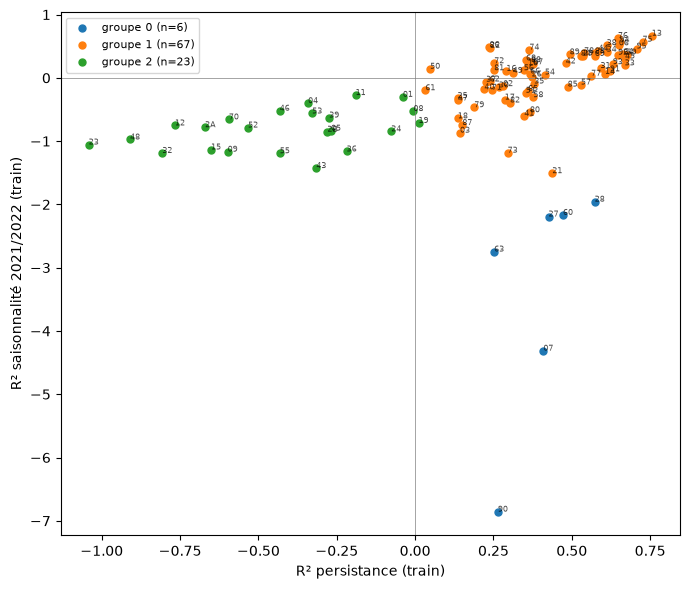

Départements répartis : 96 sur 96
R² moyen :
cluster
0    0.289
1    0.339
2   -0.059
dtype: float64


In [7]:
# figure
ind["cluster"] = KMeans(n_clusters=k_opt, n_init=20, random_state=0).fit_predict(X)

resume = ind.groupby("cluster")[["r2_persist", "r2_saison"]].mean().round(2)
resume["n_dept"] = ind["cluster"].value_counts()
print(resume)

fig, ax = plt.subplots(figsize=(7, 6))
for k, g in ind.groupby("cluster"):
    ax.scatter(g["r2_persist"], g["r2_saison"], s=25, label=f"groupe {k} (n={len(g)})")
    for dept, r in g.iterrows():
        ax.annotate(dept, (r["r2_persist"], r["r2_saison"]), fontsize=6, alpha=0.7)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("R² persistance (train)")
ax.set_ylabel("R² saisonnalité 2021/2022 (train)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Départements répartis :", resume["n_dept"].sum(), "sur", len(ind))

# R² par département, moyenne par groupe
r2_val = {}
for dept, v in v_all.groupby("code_dept"):
    r2_val[dept] = scores(v["cible"], v["pred_LR"])["R2"]
r2_val = pd.Series(r2_val)

print("R² moyen :")
print(r2_val.groupby(ind["cluster"]).mean().round(3))

In [8]:
#préparation ACP
toutes = EXOS + ["y_lag0"]
tr = panel[panel["split"] == "train"]
dep_t = tr.groupby("code_dept")[toutes].mean()
dep_t = dep_t.rename(columns={"y_lag0": CIBLE})

# Colonnes complètes et non constantes
manquants = dep_t.isna().sum()
exclues_nan = manquants[manquants > 0]
ecarts = dep_t.std()
exclues_cst = ecarts[ecarts == 0].index.tolist()
dep_t = dep_t.drop(columns=exclues_nan.index.tolist() + exclues_cst)

print("Départements :", dep_t.shape[0])
print("Variables disponibles :", len(toutes))
print("Variables conservées :", dep_t.shape[1])
print("Exclues (constantes) :", exclues_cst)
print("Exclues (manquantes) :")
print(exclues_nan)

Départements : 96
Variables disponibles : 53
Variables conservées : 53
Exclues (constantes) : []
Exclues (manquantes) :
Series([], dtype: int64)


In [9]:
METEO = ["pression_mer", "tendance_pression_3h", "vent_vitesse", "temperature_kelvin",
         "humidite_relative", "visibilite", "pression_station", "precipitation_3h"]

def famille(c):
    if c.startswith("pct_"):
        return "socio-éco"
    if c.startswith("densite_") or c == "sos_present":
        return "offre de soins"
    if c.startswith("prev_calc_") or "urgences" in c or "hospitalisation" in c:
        return "santé"
    if c.startswith("tp_") or c in METEO:
        return "météo"
    return "pollution"

# ACP sur variables standardisées
Z_t = StandardScaler().fit_transform(dep_t)
pca_t = PCA().fit(Z_t)
noms_t = []
for i in range(Z_t.shape[1]):
    noms_t.append("CP" + str(i + 1))
coord_t = pd.DataFrame(pca_t.transform(Z_t), index=dep_t.index, columns=noms_t)
variance_t = 100 * pca_t.explained_variance_ratio_

# corrélations à CP1, CP2, CP3
cor_t = pd.DataFrame(index=dep_t.columns)
for cp in ["CP1", "CP2", "CP3"]:
    cor_t[cp] = dep_t.corrwith(coord_t[cp])
cor_t["famille"] = cor_t.index.map(famille)

# part de chaque famille dans chaque composante 
carres = cor_t[["CP1", "CP2", "CP3"]] ** 2
bilan = carres.groupby(cor_t["famille"]).mean().round(2)
bilan["n_var"] = cor_t["famille"].value_counts()
print("Corrélation au carré moyenne par famille :")
print(bilan)

# variables les plus liées à chaque composante
for cp in ["CP1", "CP2", "CP3"]:
    ordre = cor_t[cp].abs().sort_values(ascending=False).index[:8]
    print("\nVariables les plus liées à", cp, ":")
    print(cor_t.loc[ordre, [cp, "famille"]].round(2))


Corrélation au carré moyenne par famille :
                 CP1   CP2   CP3  n_var
famille                                
météo           0.07  0.21  0.13     16
offre de soins  0.12  0.11  0.12      6
pollution       0.19  0.14  0.13     15
santé           0.21  0.08  0.06      8
socio-éco       0.44  0.11  0.06      8

Variables les plus liées à CP1 :
                                 CP1    famille
pct_urbain                      0.86  socio-éco
pct_retraites                  -0.85  socio-éco
pct_cadres                      0.83  socio-éco
NO2                             0.80  pollution
TousAge_asthme_urgences         0.76      santé
TousAge_asthme_hospitalisation  0.75      santé
pct_prof_inter                  0.74  socio-éco
pct_agriculteurs               -0.71  socio-éco

Variables les plus liées à CP2 :
                                            CP2         famille
humidite_relative                          0.79           météo
pct_artisans                              -0.78  

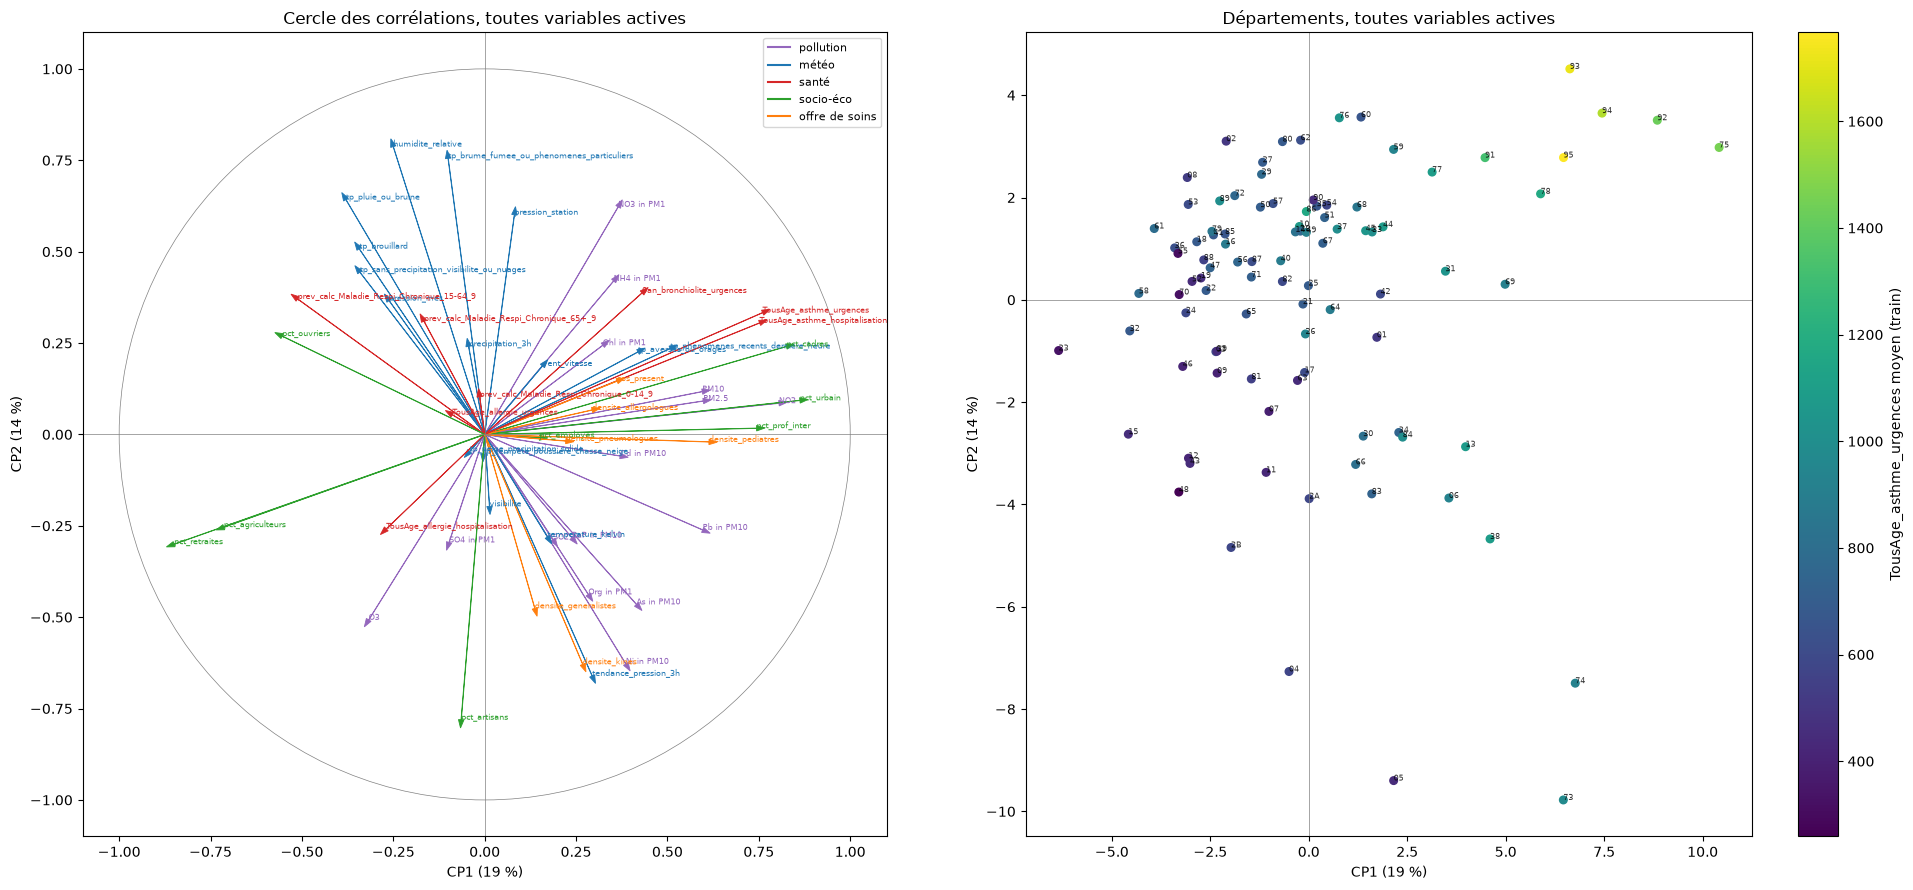

In [10]:
couleurs = {"pollution": "tab:purple", "météo": "tab:blue", "santé": "tab:red",
            "socio-éco": "tab:green", "offre de soins": "tab:orange"}

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

# cercle des corrélations, coloré par famille
ax = axes[0]
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey", lw=0.5))
for nom, r in cor_t.iterrows():
    coul = couleurs[r["famille"]]
    ax.arrow(0, 0, r["CP1"], r["CP2"], color=coul, head_width=0.015, lw=0.6)
    ax.annotate(nom, (r["CP1"], r["CP2"]), fontsize=6, color=coul)
for fam, coul in couleurs.items():
    ax.plot([], [], color=coul, label=fam)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel(f"CP1 ({variance_t[0]:.0f} %)")
ax.set_ylabel(f"CP2 ({variance_t[1]:.0f} %)")
ax.set_title("Cercle des corrélations, toutes variables actives")
ax.legend(fontsize=8, loc="upper right")

# départements sur CP1 & CP2
ax = axes[1]
sc = ax.scatter(coord_t["CP1"], coord_t["CP2"], c=dep_t[CIBLE], cmap="viridis", s=30)
for dept, r in coord_t.iterrows():
    ax.annotate(dept, (r["CP1"], r["CP2"]), fontsize=6, alpha=0.8)
plt.colorbar(sc, ax=ax, label=f"{CIBLE} moyen (train)")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel(f"CP1 ({variance_t[0]:.0f} %)")
ax.set_ylabel(f"CP2 ({variance_t[1]:.0f} %)")
ax.set_title("Départements, toutes variables actives")

plt.tight_layout()
plt.show()

#### Conclusion : il est possible de distribuer les départements sur un gradient, à l'aide des variables explicatives
#### socio-éco, santé et météo essentiellement. => retour à TousAge_allergie_urgences !